# Evaluación 3 — Modelado Predictivo de Riesgo Crediticio
### Clasificación de clientes en riesgo de impago con Árbol de Decisión

**Contexto de negocio.** Una institución financiera evalúa solicitudes de préstamos hipotecarios y
necesita anticipar el **riesgo de impago** (`Riesgo_Impago`: **1** = el cliente caerá en impago,
**0** = cumplirá sus pagos).

**Clase positiva = impago (1)**: es la clase que el banco necesita detectar.

| Error | Qué ocurre | Costo por caso |
|---|---|---|
| **Falso Negativo (FN)** · Error Tipo II | Se aprueba a un cliente que **no paga** → pérdida del capital | **\$1.500.000** |
| **Falso Positivo (FP)** · Error Tipo I | Se rechaza a un cliente que **sí habría pagado** → pérdida de intereses | **\$200.000** |

Dejar pasar un impago es **7,5 veces más caro** que rechazar a un buen cliente
(\$1.500.000 / \$200.000 = 7,5). Esta razón de costos guía la optimización y la elección de métricas.

> Reproducibilidad: `random_state = 29` en todos los procesos aleatorios (exigido por el enunciado).

In [2]:
# ============================================================
# Fase 0 — Librerías, constantes y carga de datos
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (recall_score, precision_score, f1_score, fbeta_score,
                             average_precision_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, make_scorer)

RANDOM_STATE = 29
COSTO_FP, COSTO_FN = 200_000, 1_500_000  # costo por caso según el enunciado

def clp(x):
    """Formatea un monto en pesos con separador de miles chileno."""
    return f"${x:,.0f}".replace(",", ".")

# Ruta del dataset. En Colab: subir el archivo a la sesión, o reemplazar por la URL "raw"
# del CSV dentro de la carpeta E3-Clasificación del repositorio del grupo.
RUTA_CSV = "https://raw.githubusercontent.com/ale-are/IA-Ev1/refs/heads/main/E3%20-%20Clasificacion/riesgo_crediticio.csv"

# index_col=0: la primera columna del archivo es solo un índice, no una variable del negocio.
df = pd.read_csv(RUTA_CSV, index_col=0)
df = df.drop(columns=['Unnamed: 0'], errors='ignore')   # salvaguarda por si el índice entra como columna

print("Dimensiones:", df.shape)
print("Columnas   :", list(df.columns))
df.head()

Dimensiones: (25000, 5)
Columnas   : ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso', 'Riesgo_Impago']


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,39785.55,85246.38,694.0,70.00,0
1,69773.95,244260.00,622.0,10.65,0
2,127770.68,209310.35,780.0,42.70,0
3,16799.80,213059.98,741.0,48.04,0
4,70229.83,219523.13,714.0,25.58,0


## Fase 1 — Diagnóstico y Calidad de Datos (EDA)

Se revisan tipos de datos, nulos, duplicados, inconsistencias lógicas, outliers, asimetría y —lo más
importante en este problema— el **desbalance de la variable objetivo**.

In [3]:
# 1.1 Tipos de datos y estructura
df.info()
print("\n¿Puntaje_Credito tiene solo valores enteros?:", (df['Puntaje_Credito'] % 1 == 0).all())

<class 'pandas.core.frame.DataFrame'>
Index: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 1.1 MB

¿Puntaje_Credito tiene solo valores enteros?: True


In [4]:
# 1.2 Estadísticos descriptivos
df.describe().round(2)

,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
count,25000.00,25000.00,25000.00,25000.00,25000.00
mean,55824.44,220162.89,680.03,24.03,0.07
std,29804.90,60059.30,59.78,13.62,0.26
min,7832.12,50000.00,457.00,5.00,0.00
25%,35051.32,179438.08,640.00,13.79,0.00
50%,49234.68,220241.47,680.00,21.45,0.00
75%,68923.52,261003.36,721.00,31.38,0.00
max,348135.55,451784.21,850.00,70.00,1.00


In [5]:
# 1.3 Nulos y duplicados (sobre las variables reales, ya sin la columna índice)
print("Nulos por columna:")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
Ingreso_Anual             0
Monto_Prestamo            0
Puntaje_Credito           0
Relacion_Deuda_Ingreso    0
Riesgo_Impago             0
dtype: int64

Filas duplicadas: 0


In [6]:
# 1.4 Inconsistencias lógicas de negocio
num_cols = ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']

print("Target solo contiene {0,1}       :", set(df['Riesgo_Impago'].unique()).issubset({0, 1}))
print("Ingreso_Anual <= 0               :", (df['Ingreso_Anual'] <= 0).sum())
print("Monto_Prestamo <= 0              :", (df['Monto_Prestamo'] <= 0).sum())
print("Puntaje fuera de [300, 850]      :", ((df['Puntaje_Credito'] < 300) | (df['Puntaje_Credito'] > 850)).sum())
# DTI negativo es imposible; DTI > 100 % es posible (endeudamiento extremo): se revisaría, no se elimina.
print("DTI negativo (inconsistencia)    :", (df['Relacion_Deuda_Ingreso'] < 0).sum())
print("DTI > 100 % (endeud. extremo)    :", (df['Relacion_Deuda_Ingreso'] > 100).sum())
print(f"Rango observado del DTI          : {df['Relacion_Deuda_Ingreso'].min()} % a {df['Relacion_Deuda_Ingreso'].max()} %")

Target solo contiene {0,1}       : True
Ingreso_Anual <= 0               : 0
Monto_Prestamo <= 0              : 0
Puntaje fuera de [300, 850]      : 0
DTI negativo (inconsistencia)    : 0
DTI > 100 % (endeud. extremo)    : 0
Rango observado del DTI          : 5.0 % a 70.0 %


Ingreso_Anual            asimetría= 1.70 | outliers altos= 976 (impago  1.1 %) | bajos=  0
Monto_Prestamo           asimetría=-0.00 | outliers altos=  81 (impago 24.7 %) | bajos= 76 (impago  1.3 %)
Puntaje_Credito          asimetría=-0.03 | outliers altos=  73 (impago  1.4 %) | bajos= 94 (impago 22.3 %)
Relacion_Deuda_Ingreso   asimetría= 0.99 | outliers altos= 663 (impago 46.9 %) | bajos=  0


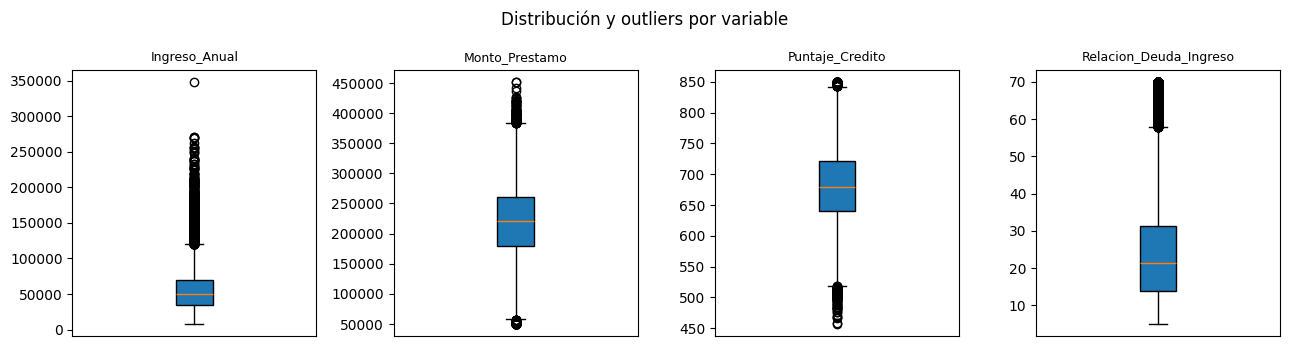

In [7]:
# 1.5 Asimetría y outliers (regla del rango intercuartílico, IQR),
#     junto con la tasa de impago de esos outliers (¿son perfiles de riesgo o no?)
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    altos, bajos = df[df[c] > q3 + 1.5*iqr], df[df[c] < q1 - 1.5*iqr]
    txt = f"{c:24} asimetría={df[c].skew():5.2f} | outliers altos={len(altos):4d}"
    if len(altos): txt += f" (impago {altos['Riesgo_Impago'].mean()*100:4.1f} %)"
    txt += f" | bajos={len(bajos):3d}"
    if len(bajos): txt += f" (impago {bajos['Riesgo_Impago'].mean()*100:4.1f} %)"
    print(txt)

fig, axs = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, c in zip(axs, num_cols):
    ax.boxplot(df[c], patch_artist=True)
    ax.set_title(c, fontsize=9); ax.set_xticks([])
fig.suptitle("Distribución y outliers por variable")
plt.tight_layout(); plt.show()

In [8]:
# 1.6 Observación fina: valores 'apilados' en los límites (posible truncamiento al generar los datos)
print("Relacion_Deuda_Ingreso == 5  :", (df['Relacion_Deuda_Ingreso'] == 5).sum())
print("Relacion_Deuda_Ingreso == 70 :", (df['Relacion_Deuda_Ingreso'] == 70).sum())
print("Monto_Prestamo == 50.000     :", (df['Monto_Prestamo'] == 50000).sum())
print("Puntaje_Credito == 850       :", (df['Puntaje_Credito'] == 850).sum())

sobreapalancado = df['Monto_Prestamo'] > 10 * df['Ingreso_Anual']
print(f"\nPréstamo > 10 veces el ingreso anual: {sobreapalancado.sum()} clientes ({sobreapalancado.mean()*100:.1f} %)")

Relacion_Deuda_Ingreso == 5  : 631
Relacion_Deuda_Ingreso == 70 : 196
Monto_Prestamo == 50.000     : 53
Puntaje_Credito == 850       : 49

Préstamo > 10 veces el ingreso anual: 1785 clientes (7.1 %)


Cumple (0):  23211  (92.84 %)
Impago (1):   1789  (7.16 %)


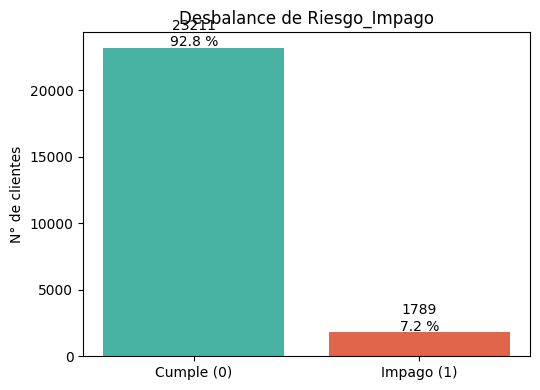

In [9]:
# 1.7 Hallazgo CLAVE: desbalance de la variable objetivo
conteo = df['Riesgo_Impago'].value_counts().sort_index()
porc   = df['Riesgo_Impago'].value_counts(normalize=True).sort_index() * 100
print(f"Cumple (0): {conteo[0]:6d}  ({porc[0]:.2f} %)")
print(f"Impago (1): {conteo[1]:6d}  ({porc[1]:.2f} %)")

fig, ax = plt.subplots(figsize=(5.5, 4))
barras = ax.bar(['Cumple (0)', 'Impago (1)'], conteo.values, color=['#46B3A3', '#E0654B'])
for r, v in zip(barras, conteo.values):
    ax.text(r.get_x() + r.get_width()/2, v + 150, f"{v}\n{v/len(df)*100:.1f} %", ha='center')
ax.set_title("Desbalance de Riesgo_Impago"); ax.set_ylabel("N° de clientes")
plt.tight_layout(); plt.show()

In [10]:
# 1.8 Relación de las variables con el impago (tasa de impago por tramos)
tramos_dti = pd.cut(df['Relacion_Deuda_Ingreso'], bins=[0, 20, 35, 50, 70], include_lowest=True)
tramos_pc  = pd.cut(df['Puntaje_Credito'], bins=[300, 600, 700, 750, 850], include_lowest=True)

print("Tasa de impago según DTI (%):")
print((df.groupby(tramos_dti, observed=True)['Riesgo_Impago'].mean() * 100).round(1))
print("\nTasa de impago según Puntaje de Crédito (%):")
print((df.groupby(tramos_pc, observed=True)['Riesgo_Impago'].mean() * 100).round(1))

Tasa de impago según DTI (%):
Relacion_Deuda_Ingreso
(-0.001, 20.0]     2.2
(20.0, 35.0]       5.9
(35.0, 50.0]      15.5
(50.0, 70.0]      36.6
Name: Riesgo_Impago, dtype: float64

Tasa de impago según Puntaje de Crédito (%):
Puntaje_Credito
(299.999, 600.0]    16.0
(600.0, 700.0]       7.9
(700.0, 750.0]       4.4
(750.0, 850.0]       2.7
Name: Riesgo_Impago, dtype: float64


### Conclusiones de la Fase 1

- **Datos completos y consistentes:** 25.000 registros y 5 columnas (4 predictoras numéricas
  `float64` y el target `int64`; `Puntaje_Credito` viene como decimal pero todos sus valores son
  enteros). **Sin nulos, sin duplicados**, target válido (solo 0/1) y **sin inconsistencias
  lógicas**: ingresos y montos positivos, puntajes dentro de [300, 850] y DTI entre 5 % y 70 %.
- **Outliers y asimetría:** `Ingreso_Anual` (asimetría 1,70; 976 outliers) y `Relacion_Deuda_Ingreso`
  (0,99; 663 outliers) tienen cola larga a la derecha. **Se conservan** porque son valores plausibles y
  **aportan información en ambos extremos**: los outliers de DTI tienen **46,9 % de impago** (perfiles de
  alto riesgo), mientras que los de ingreso alto apenas **1,1 %** (perfiles de bajo riesgo). Eliminarlos
  sesgaría al modelo. Además, el árbol de decisión es **robusto a outliers**: divide por umbrales, no
  por distancias.
- **Valores apilados:** el DTI vale exactamente 5 en 631 filas y 70 en 196; el monto vale 50.000 en
  53 y el puntaje 850 en 49. Sugiere que los datos fueron **truncados** en sus rangos al generarse.
  Además, en **1.785 clientes (7,1 %)** el préstamo supera 10 veces el ingreso anual
  (**sobreapalancamiento**).
- **Señal predictiva:** la tasa de impago sube de 2,2 % (DTI ≤ 20 %) a 36,6 % (DTI > 50 %) y baja de
  16,0 % (puntaje ≤ 600) a 2,7 % (puntaje > 750).
- **Hallazgo crítico — desbalance severo:** solo el **7,16 %** de los clientes son impagos. Por eso la
  **_accuracy_ no es adecuada como métrica principal**: un modelo que diga "todos cumplen" acertaría
  el 92,84 % sin detectar un solo impago. Las métricas deben centrarse en la **clase minoritaria**.

## Fase 2 — Limpieza y Tratamiento de Datos (Pipeline)

Se separan predictoras (`X`) y objetivo (`y`) y se define un **Pipeline de Scikit-Learn** con
`ColumnTransformer`:

- **Imputación por mediana (salvaguarda):** aunque hoy no hay nulos, `SimpleImputer(strategy='median')`
  deja el proceso preparado para solicitudes nuevas con datos faltantes. Se usa **mediana** por ser
  **robusta** frente a la asimetría y los outliers detectados.
- **Sin codificación:** todas las predictoras son numéricas; no hay categorías de texto.
- **Sin escalado:** el **árbol de decisión no requiere escalado**, porque compara cada variable contra un
  umbral propio (es invariante a la escala).
- **Prevención de fuga de datos (data leakage):** el pipeline **aprende** sus parámetros (la mediana)
  **solo con el entrenamiento** y los **aplica** al test. Dentro de `GridSearchCV` el pipeline se
  reajusta en cada pliegue, así que ningún dato de validación se filtra al entrenamiento.

In [11]:
X = df.drop(columns='Riesgo_Impago')
y = df['Riesgo_Impago']

preprocesador = ColumnTransformer(
    transformers=[('num', SimpleImputer(strategy='median'), num_cols)]
)
preprocesador

ColumnTransformer(transformers=[('num', SimpleImputer(strategy='median'),
                                 ['Ingreso_Anual', 'Monto_Prestamo',
                                  'Puntaje_Credito',
                                  'Relacion_Deuda_Ingreso'])])

## Fase 3 — Construcción del Modelo

1. **División estratificada** 80 % entrenamiento / 20 % prueba con `stratify=y`, para mantener el
   7,16 % de impagos en ambos conjuntos.
2. **Modelo base (línea base):** `DecisionTreeClassifier` con parámetros por defecto.
3. **Modelo optimizado:** `GridSearchCV` con validación cruzada estratificada de 5 pliegues, afinando
   **5 hiperparámetros**. El criterio de selección es una **función de costo financiero**
   (`FP × \$200.000 + FN × \$1.500.000`, promedio por cliente), porque el objetivo del banco depende de
   ambos errores con pesos distintos.

**Fundamento del espacio de búsqueda:**
- `max_depth` 4–12: el árbol base crece sin límite y sobreajusta; se buscan árboles acotados e
  interpretables. El rango permite comprobar que el óptimo queda **dentro** de la grilla.
- `min_samples_leaf` 20–200: con 7 % de impagos, una hoja necesita suficientes clientes para que su
  proporción de impagos sea estable.
- `min_samples_split` 2–50: tamaño mínimo de un nodo para dividirlo.
- `criterion` gini / entropy: las dos medidas de impureza vistas en clases.
- `class_weight`: cómo compensar el desbalance. Se prueban tres opciones: **sin peso** (`None`),
  **`'balanced'`** (pondera los impagos por la proporción de clases, ≈ 13:1) y **`{0: 1, 1: 7.5}`**
  (pondera los impagos según la **razón de costos del negocio**, 7,5:1).

In [12]:
# 3.1 División estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Impago en train: {y_train.mean()*100:.2f} % | en test: {y_test.mean()*100:.2f} %")

Train: (20000, 4) | Test: (5000, 4)
Impago en train: 7.16 % | en test: 7.16 %


In [13]:
# 3.2 MODELO BASE — árbol de decisión por defecto
modelo_base = Pipeline([
    ('prep', preprocesador),
    ('clf',  DecisionTreeClassifier(random_state=RANDOM_STATE))
])
modelo_base.fit(X_train, y_train)
pred_base = modelo_base.predict(X_test)

arbol_base = modelo_base.named_steps['clf']
print(f"Profundidad del árbol base: {arbol_base.get_depth()} | hojas: {arbol_base.get_n_leaves()}")

Profundidad del árbol base: 31 | hojas: 1623


In [14]:
# 3.3 MODELO OPTIMIZADO — GridSearchCV con función de costo financiero (tarda ~1-2 minutos)
def costo_por_cliente(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return (fp*COSTO_FP + fn*COSTO_FN) / len(y_true)     # $ promedio por cliente

costo_scorer = make_scorer(costo_por_cliente, greater_is_better=False)  # se MINIMIZA el costo

param_grid = {
    'clf__criterion':         ['gini', 'entropy'],
    'clf__max_depth':         [4, 6, 8, 10, 12],
    'clf__min_samples_leaf':  [20, 50, 100, 200],
    'clf__min_samples_split': [2, 10, 50],
    'clf__class_weight':      [None, 'balanced', {0: 1, 1: COSTO_FN / COSTO_FP}],  # {0:1, 1:7.5}
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(
    Pipeline([('prep', preprocesador),
              ('clf',  DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid, scoring=costo_scorer, cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

modelo_opt = grid.best_estimator_
pred_opt   = modelo_opt.predict(X_test)
arbol_opt  = modelo_opt.named_steps['clf']

print(f"Combinaciones evaluadas: {len(grid.cv_results_['params'])} x 5 pliegues")
print("Mejores hiperparámetros:")
for k, v in grid.best_params_.items():
    print(f"  {k.replace('clf__', ''):18}: {v}")
print(f"Costo promedio por cliente en validación cruzada (best_score_): {clp(-grid.best_score_)}")
print(f"Profundidad del árbol optimizado: {arbol_opt.get_depth()} | hojas: {arbol_opt.get_n_leaves()}")

Combinaciones evaluadas: 360 x 5 pliegues
Mejores hiperparámetros:
  class_weight      : {0: 1, 1: 7.5}
  criterion         : entropy
  max_depth         : 8
  min_samples_leaf  : 100
  min_samples_split : 2
Costo promedio por cliente en validación cruzada (best_score_): $68.450
Profundidad del árbol optimizado: 8 | hojas: 85


In [15]:
# 3.4 ¿Qué aportó cada hiperparámetro? Mejor costo en validación cruzada por valor
res = pd.DataFrame({
    'class_weight':      [str(p['clf__class_weight']) for p in grid.cv_results_['params']],
    'criterion':         [p['clf__criterion']         for p in grid.cv_results_['params']],
    'max_depth':         [p['clf__max_depth']         for p in grid.cv_results_['params']],
    'min_samples_leaf':  [p['clf__min_samples_leaf']  for p in grid.cv_results_['params']],
    'min_samples_split': [p['clf__min_samples_split'] for p in grid.cv_results_['params']],
    'costo_cv':          -grid.cv_results_['mean_test_score'],
})
for h in ['class_weight', 'criterion', 'max_depth', 'min_samples_leaf', 'min_samples_split']:
    mejor = res.groupby(h)['costo_cv'].min().sort_values()
    print(f"{h}:  " + " | ".join(f"{k} -> {clp(v)}" for k, v in mejor.items()))

class_weight:  {0: 1, 1: 7.5} -> $68.450 | balanced -> $73.755 | None -> $89.615
criterion:  entropy -> $68.450 | gini -> $68.645
max_depth:  8 -> $68.450 | 12 -> $68.720 | 10 -> $68.815 | 6 -> $69.660 | 4 -> $70.480
min_samples_leaf:  100 -> $68.450 | 50 -> $69.410 | 200 -> $69.485 | 20 -> $69.815
min_samples_split:  2 -> $68.450 | 10 -> $68.450 | 50 -> $68.450


**Lectura de la búsqueda:**
- **`class_weight = {0: 1, 1: 7.5}` es la opción ganadora.** Con estos pesos, una hoja del árbol se
  clasifica como "impago" cuando la proporción de impagos **de entrenamiento en esa hoja** supera
  **1 / (1 + 7,5) ≈ 11,8 %**. Ese es
  exactamente el punto en que **rechazar sale más barato que aprobar**: \$200.000 / (\$200.000 + \$1.500.000)
  ≈ 11,8 %. (Los pesos también influyen en cómo el árbol elige sus cortes, porque la impureza se calcula
  ponderada.) En cambio, `'balanced'` (≈ 13:1) rechaza desde ≈ 7 % de riesgo y castiga de más a los buenos
  clientes (\$73.755 por cliente); y sin pesos el costo es el más alto (\$89.615 por cliente), porque el árbol
  trata igual ambos errores aunque uno cueste 7,5 veces más.
- **`max_depth = 8` y `min_samples_leaf = 100`** quedan **dentro** del rango probado: tanto los valores
  menores como los mayores dan un costo algo más alto (p. ej., profundidad 12: \$68.720 vs \$68.450).
  Las diferencias son pequeñas frente a la variabilidad entre pliegues, pero el óptimo no está en un
  borde de la grilla.
- **`criterion`:** entropy gana por poco (diferencia de \$195 por cliente, muy inferior a la variación
  entre pliegues, ≈ \$3.600): en la práctica son equivalentes.
- **`min_samples_split`:** sus valores **empatan**. Con `min_samples_leaf = 100`, un nodo necesita al
  menos 200 clientes para poder dividirse, así que esa restricción domina a `min_samples_split`.

In [16]:
# 3.5 Control de sobreajuste: entrenamiento vs prueba
for nombre, modelo in [("Base", modelo_base), ("Optimizado", modelo_opt)]:
    r_tr = recall_score(y_train, modelo.predict(X_train))
    r_te = recall_score(y_test,  modelo.predict(X_test))
    print(f"{nombre:10} Recall train = {r_tr:.3f} | Recall test = {r_te:.3f}")

Base       Recall train = 1.000 | Recall test = 0.316
Optimizado Recall train = 0.655 | Recall test = 0.637


**Lectura:** el árbol base crece sin límite (31 niveles y 1.623 hojas) y **memoriza** el
entrenamiento (recall 1,000), pero en datos nuevos cae a 0,316: está **sobreajustado**. El árbol
optimizado, acotado a 8 niveles y hojas de al menos 100 clientes, rinde parecido en entrenamiento y
prueba: **generaliza**.

In [17]:
# 3.6 Prueba de robustez del pipeline: una solicitud nueva con un dato faltante
solicitud = X_test.iloc[[0]].copy()
solicitud['Puntaje_Credito'] = np.nan
print(solicitud)
print("\nPredicción del modelo optimizado (1 = impago):", modelo_opt.predict(solicitud)[0],
      "-> el imputador completó el faltante con la mediana del entrenamiento")

       Ingreso_Anual  Monto_Prestamo  Puntaje_Credito  Relacion_Deuda_Ingreso
24009       52250.29       108418.54              NaN                   43.23

Predicción del modelo optimizado (1 = impago): 0 -> el imputador completó el faltante con la mediana del entrenamiento


## Fase 4 — Evaluación e Interpretación de Métricas

### 4.1 Selección y justificación de las DOS métricas
Por el **desbalance** (7,16 % de impagos) y el **costo asimétrico**, se descarta la accuracy como
métrica principal y se seleccionan:

1. **Recall (de la clase impago)** = `VP / (VP + FN)`: de todos los impagos reales, ¿cuántos detecta el
   modelo? Es la métrica indicada cuando el **Falso Negativo es crítico**: cada FN cuesta \$1.500.000.
2. **Average Precision (AP)**: resume en un solo número la **curva Precision-Recall**, es decir, el
   equilibrio entre precisión y recall en **todos los umbrales**, centrado solo en la **clase positiva**.
   Se calcula con `average_precision_score` como un promedio ponderado de la precisión en cada umbral; es
   una medida del área bajo la curva PR (PR-AUC en la materia), aunque no idéntica a su integración
   trapezoidal. No usa los Verdaderos Negativos, por lo que **no se infla** con la gran mayoría de clientes
   cumplidores (a diferencia de ROC-AUC). Su línea de azar es la proporción de impagos (≈ 0,072).

**Coherencia:** el **costo financiero** es el criterio utilizado para seleccionar el modelo optimizado, mientras que Recall y Average Precision (AP) permiten evaluar su desempeño.

El Recall mide la proporción de impagos reales que el modelo detecta, permitiendo evaluar su capacidad para reducir los falsos negativos (FN), el error más costoso.

Por su parte, la AP resume el comportamiento de Precision y Recall a distintos umbrales, permitiendo evaluar qué tan confiables son las alertas de impago a medida que aumenta la detección de clientes riesgosos.

Los falsos positivos (FP) y falsos negativos (FN) obtenidos con el umbral de clasificación utilizado se analizan mediante la matriz de confusión, donde también se cuantifica su impacto financiero.

Como **apoyo** se reportan Precision, F1, F2 y ROC-AUC (métricas complementarias, no seleccionadas).

In [18]:
# 4.1 Métricas seleccionadas sobre el conjunto de prueba
proba_base = modelo_base.predict_proba(X_test)[:, 1]
proba_opt  = modelo_opt.predict_proba(X_test)[:, 1]
azar = y_test.mean()

print(f"{'':12}{'Recall':>10}{'AP':>10}{'AP / azar':>14}")
for nombre, pred, proba in [("Base", pred_base, proba_base), ("Optimizado", pred_opt, proba_opt)]:
    ap = average_precision_score(y_test, proba)
    print(f"{nombre:12}{recall_score(y_test, pred):10.3f}{ap:10.3f}{ap/azar:13.1f}x")
print(f"\nLínea de azar de la AP (proporción de impagos en test): {azar:.3f}")
print("Valores distintos de probabilidad que entrega el árbol base:", np.unique(proba_base))

                Recall        AP     AP / azar
Base             0.316     0.140          2.0x
Optimizado       0.637     0.386          5.4x

Línea de azar de la AP (proporción de impagos en test): 0.072
Valores distintos de probabilidad que entrega el árbol base: [0. 1.]


In [19]:
# 4.1b Métricas complementarias (apoyo a la interpretación; no son las seleccionadas)
print(f"{'':12}{'Precision':>11}{'F1':>8}{'F2':>8}{'ROC-AUC':>10}")
for nombre, pred, proba in [("Base", pred_base, proba_base), ("Optimizado", pred_opt, proba_opt)]:
    print(f"{nombre:12}{precision_score(y_test, pred):11.3f}{f1_score(y_test, pred):8.3f}"
          f"{fbeta_score(y_test, pred, beta=2):8.3f}{roc_auc_score(y_test, proba):10.3f}")

              Precision      F1      F2   ROC-AUC
Base              0.288   0.301   0.310     0.628
Optimizado        0.281   0.390   0.508     0.846


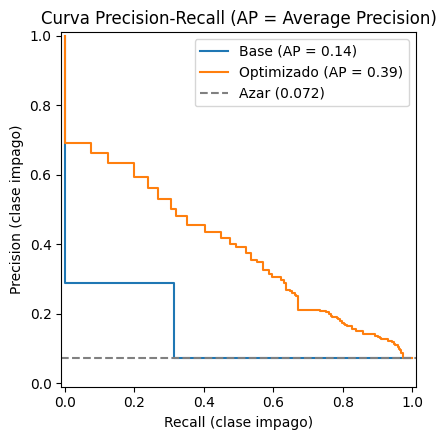

In [20]:
# 4.1c Curva Precision-Recall de ambos modelos
fig, ax = plt.subplots(figsize=(6, 4.5))
PrecisionRecallDisplay.from_predictions(y_test, proba_base, name="Base", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_opt,  name="Optimizado", ax=ax)
ax.axhline(azar, ls='--', color='gray', label=f"Azar ({azar:.3f})")
ax.set_xlabel("Recall (clase impago)"); ax.set_ylabel("Precision (clase impago)")
ax.set_title("Curva Precision-Recall (AP = Average Precision)")
ax.legend(); plt.tight_layout(); plt.show()

**Nota sobre la curva del modelo base:** como el árbol base crece hasta tener hojas puras, entrega
únicamente probabilidades 0 y 1. Por eso su curva Precision-Recall presenta **un solo punto operativo no
trivial**, además de los extremos (el escalón del gráfico), y proporciona una evaluación limitada de su
comportamiento ante diferentes umbrales de decisión. El árbol optimizado entrega probabilidades
graduadas, por lo que su curva recorre muchos umbrales.

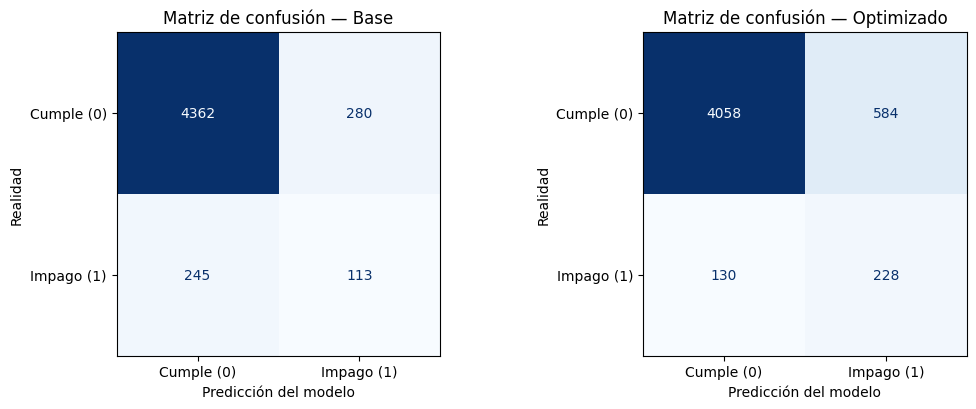

In [21]:
# 4.2 Matrices de confusión de ambos modelos (filas = realidad, columnas = predicción)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (nombre, pred) in zip(axs, [("Base", pred_base), ("Optimizado", pred_opt)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=['Cumple (0)', 'Impago (1)']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f"Matriz de confusión — {nombre}")
    ax.set_xlabel("Predicción del modelo"); ax.set_ylabel("Realidad")
plt.tight_layout(); plt.show()

In [22]:
# 4.2b Traducción de la matriz al impacto financiero
def costo_negocio(nombre, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    costo = fp*COSTO_FP + fn*COSTO_FN
    print(f"{nombre}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")
    print(f"   FN: {fn:>5} x $1.500.000 = {clp(fn*COSTO_FN)}")
    print(f"   FP: {fp:>5} x   $200.000 = {clp(fp*COSTO_FP)}")
    print(f"   Costo total            = {clp(costo)}")
    print(f"   Solicitudes rechazadas: {fp+tp} ({(fp+tp)/len(y_true)*100:.1f} %) | "
          f"buenos clientes rechazados: {fp/(tn+fp)*100:.1f} % | "
          f"impagos aprobados: {fn/(fn+tp)*100:.1f} %\n")
    return costo, fp, fn

c_base, fp_b, fn_b = costo_negocio("MODELO BASE", y_test, pred_base)
c_opt,  fp_o, fn_o = costo_negocio("MODELO OPTIMIZADO", y_test, pred_opt)

print(f"Ahorro del modelo optimizado: {clp(c_base - c_opt)} ({(c_base - c_opt)/c_base*100:.1f} %)")
print(f"   = {fn_b - fn_o} FN evitados x $1.500.000 ({clp((fn_b - fn_o)*COSTO_FN)})"
      f" - {fp_o - fp_b} FP adicionales x $200.000 ({clp((fp_o - fp_b)*COSTO_FP)})")

n_imp, n_cumpl = int(y_test.sum()), int((y_test == 0).sum())
print("\nReferencias sobre los mismos 5.000 clientes de prueba:")
print(f"   Aprobar a todos  (todos FN): {clp(n_imp*COSTO_FN)}")
print(f"   Rechazar a todos (todos FP): {clp(n_cumpl*COSTO_FP)}")

MODELO BASE: VN=4362  FP=280  FN=245  VP=113
   FN:   245 x $1.500.000 = $367.500.000
   FP:   280 x   $200.000 = $56.000.000
   Costo total            = $423.500.000
   Solicitudes rechazadas: 393 (7.9 %) | buenos clientes rechazados: 6.0 % | impagos aprobados: 68.4 %

MODELO OPTIMIZADO: VN=4058  FP=584  FN=130  VP=228
   FN:   130 x $1.500.000 = $195.000.000
   FP:   584 x   $200.000 = $116.800.000
   Costo total            = $311.800.000
   Solicitudes rechazadas: 812 (16.2 %) | buenos clientes rechazados: 12.6 % | impagos aprobados: 36.3 %

Ahorro del modelo optimizado: $111.700.000 (26.4 %)
   = 115 FN evitados x $1.500.000 ($172.500.000) - 304 FP adicionales x $200.000 ($60.800.000)

Referencias sobre los mismos 5.000 clientes de prueba:
   Aprobar a todos  (todos FN): $537.000.000
   Rechazar a todos (todos FP): $928.400.000


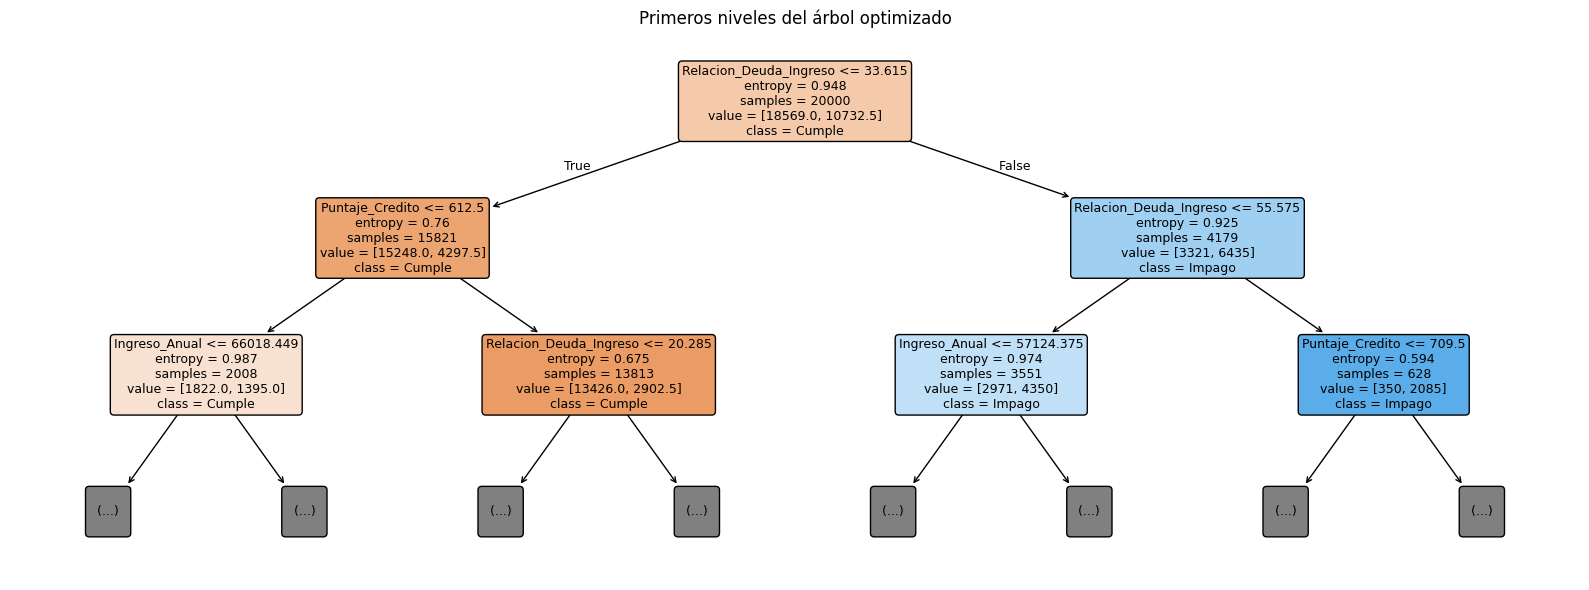

Importancia de variables dentro de este modelo:
  Relacion_Deuda_Ingreso  : 0.537
  Puntaje_Credito         : 0.187
  Ingreso_Anual           : 0.149
  Monto_Prestamo          : 0.128


In [23]:
# 4.3 Reglas del árbol optimizado (primeros niveles) e importancia de variables
# Nota: con class_weight, los conteos 'value' de cada nodo aparecen PONDERADOS (impagos x 7,5).
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(arbol_opt, feature_names=num_cols, class_names=['Cumple', 'Impago'],
          max_depth=2, filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Primeros niveles del árbol optimizado")
plt.tight_layout(); plt.show()

print("Importancia de variables dentro de este modelo:")
for n, i in sorted(zip(num_cols, arbol_opt.feature_importances_), key=lambda t: -t[1]):
    print(f"  {n:24}: {i:.3f}")

### 4.4 Interpretación en el negocio

**Resumen sobre el conjunto de prueba (5.000 clientes; 358 impagos reales):**

| | Modelo Base | Modelo Optimizado |
|---|---|---|
| **Recall** (seleccionada) | 0,316 | **0,637** |
| **Average Precision (AP)** (seleccionada) | 0,140 | **0,386** |
| Verdaderos Negativos (buenos aprobados) | 4.362 | 4.058 |
| Verdaderos Positivos (impagos detectados) | 113 | 228 |
| Falsos Negativos · Error Tipo II (impagos aprobados) | **245** | **130** |
| Falsos Positivos · Error Tipo I (buenos rechazados) | 280 | 584 |
| **Costo total estimado** | **\$423.500.000** | **\$311.800.000** |

**Métricas en idioma de negocio.**
- **Recall:** El modelo base detecta 3 de cada 10 impagos, mientras que el optimizado detecta más de 6 de cada 10 (63,7 %). Esto significa que el modelo optimizado identifica como riesgosos a la mayoría de los clientes que incurrirían en impago, permitiendo al banco revisar sus solicitudes antes de aprobarlas.

- **Average Precision:** El modelo optimizado alcanza 0,386, equivalente a aproximadamente 5,4 veces la referencia aleatoria (0,072), mientras que el modelo base obtiene 0,140 (aproximadamente 2 veces). Esto indica que el modelo optimizado presenta una mayor capacidad para priorizar a los clientes que realmente incurrirían en impago, manteniendo un mejor equilibrio global entre la detección y la confiabilidad de las alertas.

**Matriz de confusión — Modelo Base.** Aprueba correctamente a 4.362 buenos pagadores (VN) y detecta 113
impagos (VP), pero **aprueba a 245 de los 358 clientes que no pagarán (68,4 %)**. Esos 245 FN cuestan
**\$367,5 millones, el 86,8 % de su costo total** (\$423,5 millones). Rechaza por error a 280 buenos
clientes (FP, \$56 millones). Detecta solo 3 de cada 10 impagos y su costo es apenas un **21 % menor
que aprobar a todos sin modelo** (\$537 millones).

**Matriz de confusión — Modelo Optimizado.** Los FN bajan de 245 a **130** (\$195 millones) y los FP
suben de 280 a **584** (\$116,8 millones). El modelo rechaza al **16,2 % de las solicitudes** y, en
particular, al **12,6 % de los buenos clientes**: ese es su **costo comercial**. Se acepta porque cambia
el error caro por el barato:

> 115 FN evitados × \$1.500.000 = \$172,5 M − 304 FP adicionales × \$200.000 = \$60,8 M
> → **ahorro neto de \$111,7 millones (26,4 %)**.

Frente a aprobar a todos (\$537 millones), el modelo optimizado reduce el costo en un **42 %**.

**F1 (complementaria).** También mejora (0,301 → 0,390): el modelo optimizado no solo detecta más
impagos, sino que lo hace con una precisión similar (0,288 → 0,281).

**Variables.** La **Relación Deuda/Ingreso (DTI)** es la variable de **mayor importancia en este modelo**
(~54 %) y la **primera pregunta del árbol es "¿DTI ≤ 33,6 %?"**; le siguen el puntaje de crédito (~19 %),
el ingreso y el monto. No implica causalidad: indica qué variable usa más el modelo para separar clientes.

### Recomendaciones
1. **Priorizar el modelo optimizado para su evaluación operativa:** reduce en un **26,4 %** el costo
   financiero estimado en el conjunto de prueba y detecta **el doble de impagos** que el modelo base.
   Como todavía rechaza al 12,6 % de los buenos clientes, conviene usarlo al inicio como **herramienta de
   apoyo** a la evaluación crediticia, con **revisión manual** de los casos rechazados.
2. **Revisión reforzada de clientes con DTI alto:** el árbol separa primero a los clientes con DTI mayor a
   ~33,6 %, por lo que ese grupo merece un análisis más detallado.
3. **Recuperar buenos clientes rechazados:** ofrecer una segunda evaluación o condiciones alternativas
   (menor monto, aval) para reducir la pérdida comercial de los FP.
4. **Mantener el modelo alineado con los costos:** si cambian los costos de FN o FP, se deben recalcular los
   pesos de clase (y, si se ajusta el umbral de decisión, hacerlo con validación cruzada sobre el
   entrenamiento, nunca sobre el test).